# Normal Distribution

Companion notebook for the [normal distribution note](../../notes/random_variables_and_distributions/continuous/normal_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/normal_distribution.md).

$X\sim N(\mu,\sigma^2)$:

$$f(x)=\frac1{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}},\qquad F(x)=\tfrac12\left[1+\operatorname{erf}\!\left(\frac{x-\mu}{\sigma\sqrt2}\right)\right].$$

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations
from scipy.special import erf

## Hand-rolled implementation

In [2]:
class NormalDistribution:
    def __init__(self, mu, sigma):
        self.mu = mu
        self.sigma = sigma

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        return np.exp(-0.5 * ((x - self.mu) / self.sigma) ** 2) / (self.sigma * np.sqrt(2 * np.pi))

    def cdf(self, x):
        x = np.asarray(x, dtype=float)
        return 0.5 * (1 + erf((x - self.mu) / (self.sigma * np.sqrt(2))))

## Check against `scipy.stats`

In [3]:
mu1, s1 = 0, 1
mu2, s2 = 2, 1.5
x = np.linspace(-5, 7, 1000)
d1, d2 = NormalDistribution(mu1, s1), NormalDistribution(mu2, s2)

pdf1, pdf2 = stats.norm.pdf(x, mu1, s1), stats.norm.pdf(x, mu2, s2)
cdf1, cdf2 = stats.norm.cdf(x, mu1, s1), stats.norm.cdf(x, mu2, s2)
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("CDF matches:", np.allclose(d1.cdf(x), cdf1), np.allclose(d2.cdf(x), cdf2))

PDF matches: True True
CDF matches: True True


## Shape of the PDF and CDF

$\mu$ shifts the curve and $\sigma$ stretches it; the peak height is $1/(\sigma\sqrt{2\pi})$, so a wider curve is lower.

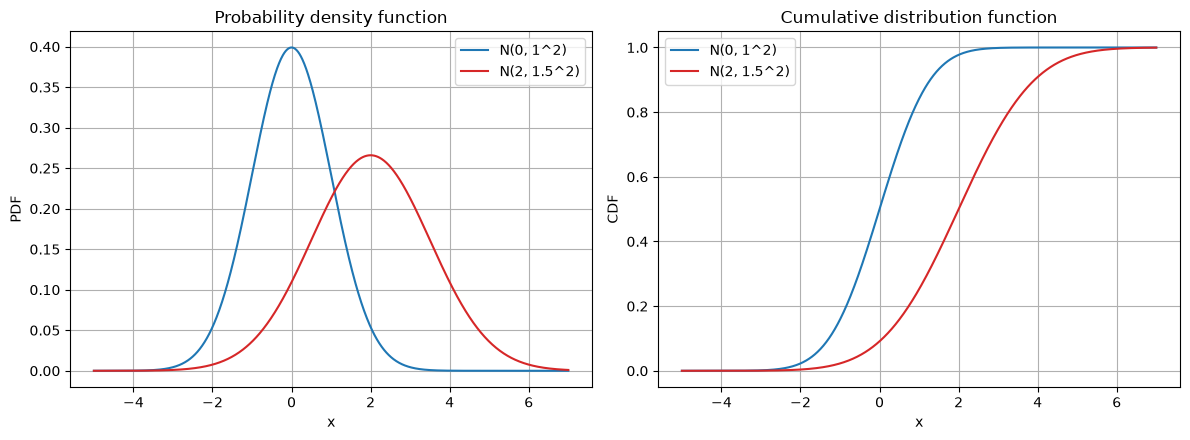

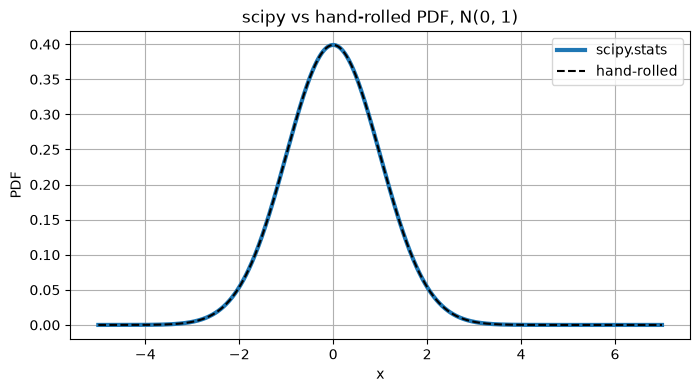

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"N({mu1}, {s1}^2)", pdf2, cdf2, f"N({mu2}, {s2}^2)")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, N(0, 1)")

## Worked example: standardizing test scores and the empirical rule

Scores are $N(70,10^2)$ and a student scores 85, so $z=(85-70)/10=1.5$ and the percentile is $\Phi(1.5)\approx0.933$. The probabilities within $k\sigma$ are $2\Phi(k)-1$.

In [5]:
scores = NormalDistribution(70, 10)
z = (85 - 70) / 10
print(f"z = {z}, percentile = {scores.cdf(85.0):.4f}  (Phi(1.5) = {stats.norm.cdf(1.5):.4f})")
print(f"75th percentile score: {stats.norm.ppf(0.75, 70, 10):.2f}")

for k in (1, 2, 3):
    exact = d1.cdf(k) - d1.cdf(-k)
    print(f"P(|Z| < {k}) = {exact:.4f}")

z = 1.5, percentile = 0.9332  (Phi(1.5) = 0.9332)
75th percentile score: 76.74
P(|Z| < 1) = 0.6827
P(|Z| < 2) = 0.9545
P(|Z| < 3) = 0.9973


## Sums of independent normals and the sample mean

If $X_i\sim N(\mu,\sigma^2)$ are independent then $\bar X\sim N(\mu,\sigma^2/n)$. We verify with simulated means of $n=25$ scores and the probability $P(\bar X>73)$.

sd of sample mean: simulated 1.997  theory 2.000
P(mean > 73): simulated 0.0670  theory 0.0668


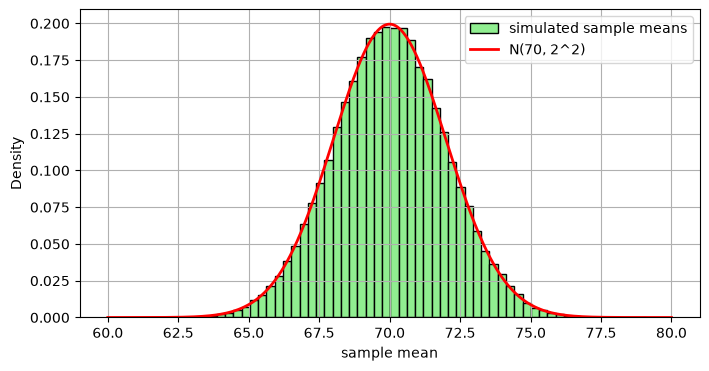

In [6]:
n = 25
means = rng.normal(70, 10, size=(100_000, n)).mean(axis=1)
print(f"sd of sample mean: simulated {means.std():.3f}  theory {10 / math.sqrt(n):.3f}")
print(f"P(mean > 73): simulated {(means > 73).mean():.4f}  theory {stats.norm.sf(73, 70, 10 / math.sqrt(n)):.4f}")

xs = np.linspace(60, 80, 400)
plt.figure(figsize=(8, 4))
plt.hist(means, bins=60, density=True, color="lightgreen", edgecolor="black", label="simulated sample means")
plt.plot(xs, stats.norm.pdf(xs, 70, 10 / math.sqrt(n)), "r-", linewidth=2, label="N(70, 2^2)")
plt.xlabel("sample mean")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* The CDF is $\Phi$, expressed through `erf`; there is no elementary antiderivative of the density.
* Standardizing with $z=(x-\mu)/\sigma$ reduces every normal calculation to $N(0,1)$.
* Means of $n$ independent normal observations have standard deviation $\sigma/\sqrt n$.